## Clustering: Jerárquico aglomerativo

- **Se ejecuta en local (scipy)** sobre una muestra de 2000 puntos: necesita la matriz de distancias completa,
  O(n²) en memoria y ~O(n²) en tiempo
- Objetivo: el **dendrograma** (cómo se fusionan los grupos a distintas escalas) y validar el k de KMeans
- Se comparan los enlaces Ward, average, complete y single con la **correlación cofenética** (qué tan fiel es el árbol a
  las distancias originales)

### Imports

In [1]:
import os, socket, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 40)

### Utilidades

- Constantes

In [2]:
SECCION, NOTEBOOK = "02_Clustering", "d_jerarquico"

proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent

final_dir = proyecto / "data" / "final"
artef_dir = proyecto / "data" / "artefactos"
clus_dir  = proyecto / "data" / "clustering"
clus_dir.mkdir(parents=True, exist_ok=True)
SUJETOS = {"entidad": "entidad_key", "proveedor": "proveedor_key"}
SEED = 42

out_dir = proyecto / SECCION / "temp" / NOTEBOOK
fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
for d in (fig_dir, tab_dir, web_dir):
    d.mkdir(parents=True, exist_ok=True)

def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()

def leer(directorio, nombre):
    return spark.read.parquet(str(directorio / nombre))

- Spark

In [3]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName(NOTEBOOK)
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "4g"))
           .config("spark.sql.shuffle.partitions", "24")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima")
           .config("spark.sql.execution.arrow.pyspark.enabled", "true"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

### Verificación del cluster

In [4]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()
print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

Master        : spark://spark-master:7077
Executors     : 0
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [5]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score, adjusted_rand_score

config = json.loads((clus_dir / "config.json").read_text())
N_JER = 2000
METODOS = ["ward", "average", "complete", "single"]

---
### 1. Comparación de enlaces

In [6]:
comparacion, Zs, muestras = [], {}, {}
for s, cfg in config.items():
    key, k = cfg["key"], cfg["k"]
    loc = (pd.read_parquet(clus_dir / f"local_{s}")
             .merge(pd.read_parquet(clus_dir / f"kmeans_{s}")[[key, "cluster"]].rename(columns={"cluster": "kmeans"}), on=key))
    m = loc.sample(n=min(N_JER, len(loc)), random_state=SEED).reset_index(drop=True)
    X = m[[f"pc_{i}" for i in range(cfg["n_comp"])]].to_numpy()
    D = pdist(X)
    res = m[[key, "kmeans"]].copy()
    for metodo in METODOS:
        Z = linkage(X, method=metodo)
        lab = fcluster(Z, t=k, criterion="maxclust")
        res[metodo] = lab
        Zs[(s, metodo)] = Z
        comparacion.append({"sujeto": s, "metodo": metodo, "k": k,
                            "cofenetica": round(float(cophenet(Z, D)[0]), 3),
                            "silhouette": round(float(silhouette_score(X, lab)), 3) if len(set(lab)) > 1 else np.nan,
                            "ari_vs_kmeans": round(float(adjusted_rand_score(m.kmeans, lab)), 3),
                            "pct_cluster_mayor": round(float(pd.Series(lab).value_counts(normalize=True).iloc[0]), 3)})
    muestras[s] = res
    spark.createDataFrame(res).write.mode("overwrite").parquet(str(clus_dir / f"jerarquico_{s}"))
comparacion = pd.DataFrame(comparacion)
comparacion

,sujeto,metodo,k,cofenetica,silhouette,ari_vs_kmeans,pct_cluster_mayor
0,entidad,ward,3,0.427,0.218,0.375,0.562
1,entidad,average,3,0.778,0.574,0.000,0.980
2,entidad,complete,3,0.617,0.485,0.047,0.962
3,entidad,single,3,0.671,0.585,-0.007,0.983
4,proveedor,ward,3,0.602,0.254,0.663,0.736
5,proveedor,average,3,0.773,0.402,0.097,0.973
6,proveedor,complete,3,0.650,0.315,0.498,0.842
7,proveedor,single,3,0.683,0.371,0.006,0.999


- **Single** suele tener cofenética alta pero produce "encadenamiento": un clúster gigante (`pct_cluster_mayor` ≈ 1) y
  singletons, inútil como tipología
- **Ward** minimiza la varianza intra-grupo (el mismo objetivo que KMeans): un ARI alto con KMeans confirma que las
  tipologías no dependen del algoritmo

### 2. Dendrograma (Ward)

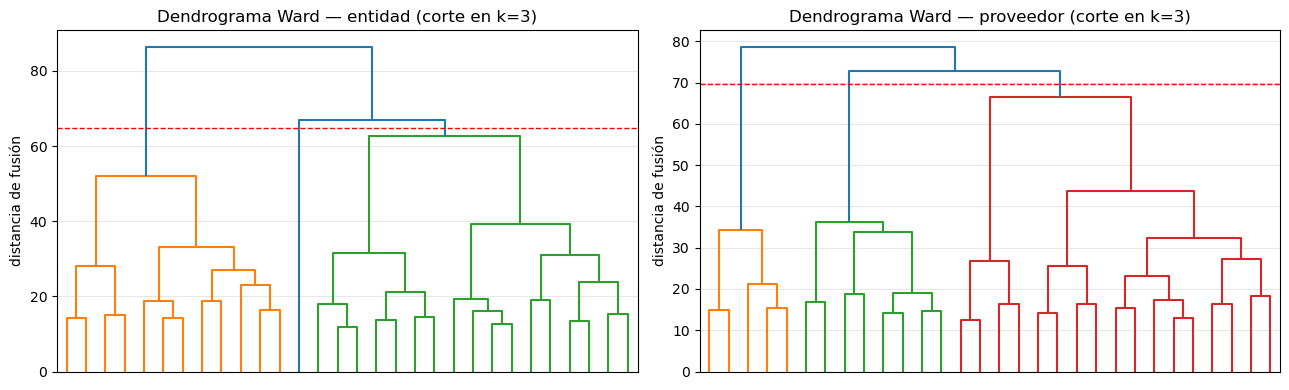

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, s in enumerate(config):
    Z, k = Zs[(s, "ward")], config[s]["k"]
    corte = (Z[-k, 2] + Z[-(k - 1), 2]) / 2
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax[i], no_labels=True, color_threshold=corte)
    ax[i].axhline(corte, color="red", ls="--", lw=1)
    ax[i].set_title(f"Dendrograma Ward — {s} (corte en k={k})"); ax[i].set_ylabel("distancia de fusión")
mostrar_fig("dendrogramas")

- Un salto grande en la altura de fusión justo antes del corte indica que k grupos es una partición natural.
  Si el salto mayor aparece en otro nivel, es evidencia para revisar `K_FIJO` en `b_kmeans`

### 3. Escritura de resultados (incluye el linkage para recortar el árbol en la web)

In [8]:
linkages = {f"linkage_ward_{s}": pd.DataFrame(Zs[(s, "ward")], columns=["a", "b", "distancia", "n"]) for s in config}
tablas = {"comparacion_enlaces": comparacion, **linkages,
          **{f"muestra_jerarquico_{s}": mp for s, mp in muestras.items()}}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en {SECCION}/temp/{NOTEBOOK}/: {', '.join(escritos)}")

Escrito en 02_Clustering/temp/d_jerarquico/: comparacion_enlaces, linkage_ward_entidad, linkage_ward_proveedor, muestra_jerarquico_entidad, muestra_jerarquico_proveedor


#### a. Verificación

In [9]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"
figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json)" + (f" | {len(figs)} figuras: {', '.join(figs)}" if figs else ""))

OK: 5 tablas (parquet + json) | 1 figuras: dendrogramas


---
### 4. Cerrar sesión

In [10]:
spark.stop()